In [1]:

import numpy as np
import pandas as pd


In [2]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

In [3]:
df.head

<bound method NDFrame.head of          id  gender   age  hypertension  heart_disease ever_married  \
0      9046    Male  67.0             0              1          Yes   
1     51676  Female  61.0             0              0          Yes   
2     31112    Male  80.0             0              1          Yes   
3     60182  Female  49.0             0              0          Yes   
4      1665  Female  79.0             1              0          Yes   
...     ...     ...   ...           ...            ...          ...   
5105  18234  Female  80.0             1              0          Yes   
5106  44873  Female  81.0             0              0          Yes   
5107  19723  Female  35.0             0              0          Yes   
5108  37544    Male  51.0             0              0          Yes   
5109  44679  Female  44.0             0              0          Yes   

          work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0           Private          Urban   

In [4]:
df= df.drop('id' ,axis=1)

In [5]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [6]:
repeated_features = ['gender', 'hypertension', 'heart_disease', 'work_type', 'ever_married' , 'Residence_type', 'smoking_status']
unique_features = {col:df[col].unique() for col in repeated_features}

In [7]:
unique_features

{'gender': array(['Male', 'Female', 'Other'], dtype=object),
 'hypertension': array([0, 1]),
 'heart_disease': array([1, 0]),
 'work_type': array(['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked'],
       dtype=object),
 'ever_married': array(['Yes', 'No'], dtype=object),
 'Residence_type': array(['Urban', 'Rural'], dtype=object),
 'smoking_status': array(['formerly smoked', 'never smoked', 'smokes', 'Unknown'],
       dtype=object)}

In [8]:
for col, features in unique_features.items():
    print(f"{col} : {features}")

gender : ['Male' 'Female' 'Other']
hypertension : [0 1]
heart_disease : [1 0]
work_type : ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
ever_married : ['Yes' 'No']
Residence_type : ['Urban' 'Rural']
smoking_status : ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 439.3+ KB


# seems like a classsification problem


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [12]:
y = df['stroke']
y.value_counts(normalize = True)

stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64

imbalance  xa since 95% data is tilted towards 0 so this should be looked into

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt


<BarContainer object of 2 artists>

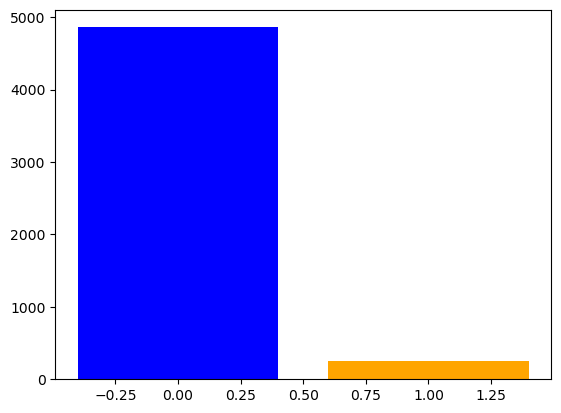

In [14]:

plt.bar(x=y.value_counts().index, height=y.value_counts(), color=['blue', 'orange'])


so accuracy ko paxadi lagana bhyena

In [15]:
numerical_features = ['age' , 'avg_glucose_level', 'bmi']
df[numerical_features].describe()

,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000


<Axes: xlabel='bmi', ylabel='Count'>

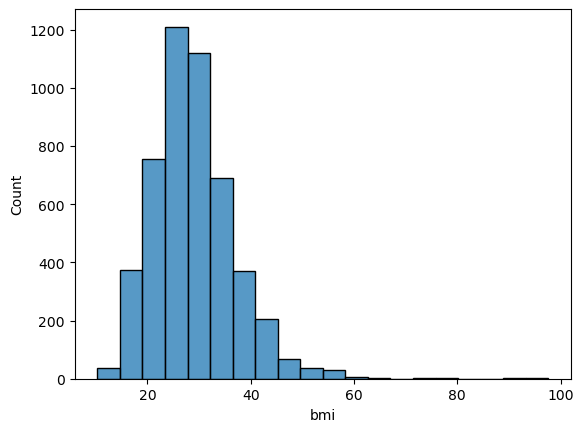

In [16]:
sns.histplot(data=df[numerical_features], x="bmi" ,bins=20)


<Axes: xlabel='age', ylabel='Count'>

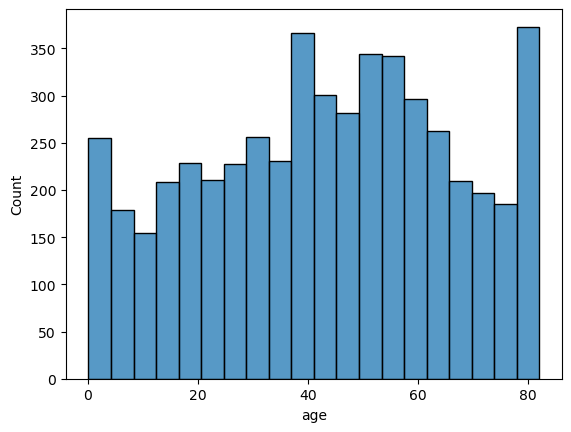

In [17]:
sns.histplot(data=df[numerical_features], x="age" ,bins=20)


<Axes: xlabel='avg_glucose_level', ylabel='Count'>

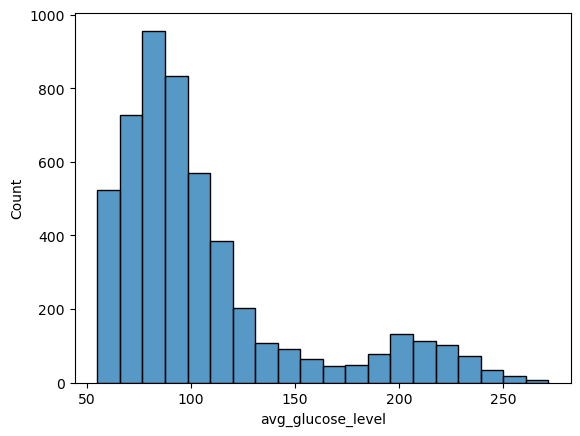

In [18]:
sns.histplot(data=df[numerical_features], x="avg_glucose_level" ,bins=20)


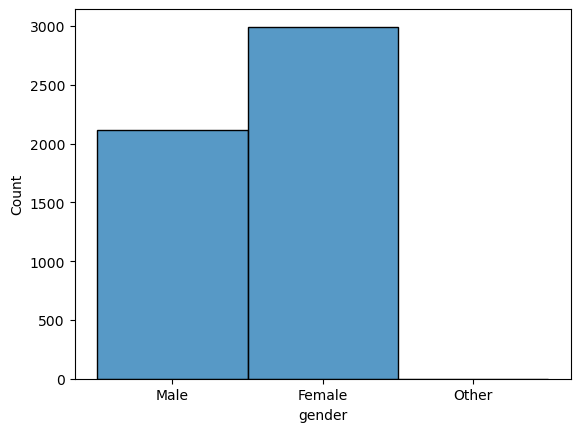

In [19]:
fig = sns.histplot(df, x= 'gender' )


female are more than male in the data


In [20]:
round(df[df['gender']=='Male']['stroke'].mean()*100,2)

np.float64(5.11)

In [21]:
round(df[df['gender']=='Female']['stroke'].mean()*100,2)

np.float64(4.71)

hence it is seen that male have a higher chance of getting strokes 

similarly exploring more visuals 


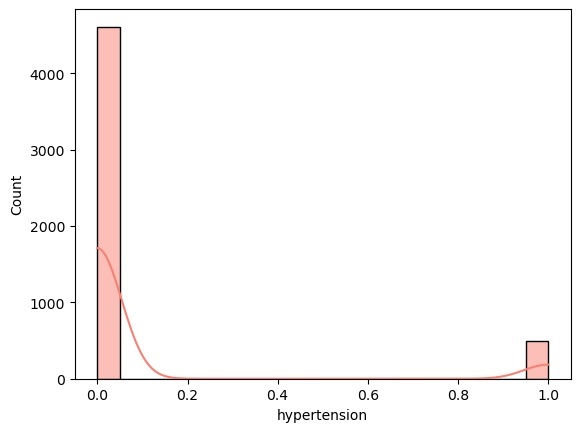

In [22]:
fig = sns.histplot(df, x= 'hypertension' , bins = 20 , color= 'salmon' , kde = True )


In [23]:
round(df[df['hypertension']==0]['stroke'].mean()*100,2)

np.float64(3.97)

In [24]:
round(df[df['hypertension']==1]['stroke'].mean()*100,2)

np.float64(13.25)

similar to others also


In [25]:
predict_from_worktype = df.groupby('work_type')['stroke'].mean()*100
predict_from_worktype.sort_values(ascending=True)


work_type
Never_worked     0.000000
children         0.291121
Govt_job         5.022831
Private          5.094017
Self-employed    7.936508
Name: stroke, dtype: float64

In [26]:
df[numerical_features+['stroke']].corr()

,age,avg_glucose_level,bmi,stroke
age,1.000000,0.238171,0.333398,0.245257
avg_glucose_level,0.238171,1.000000,0.175502,0.131945
bmi,0.333398,0.175502,1.000000,0.042374
stroke,0.245257,0.131945,0.042374,1.000000


Text(0.5, 1.0, 'Correlation Heatmap')

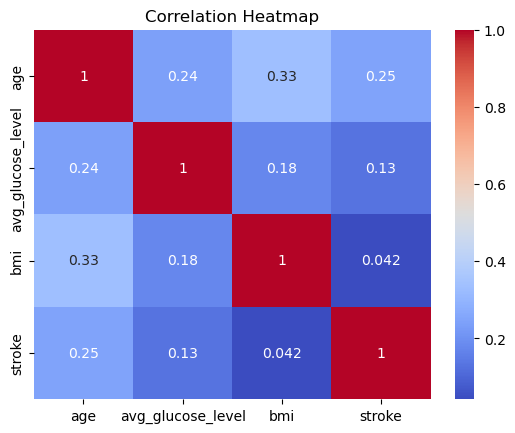

In [27]:
sns.heatmap(df[numerical_features + ['stroke']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')

<Axes: xlabel='stroke', ylabel='age'>

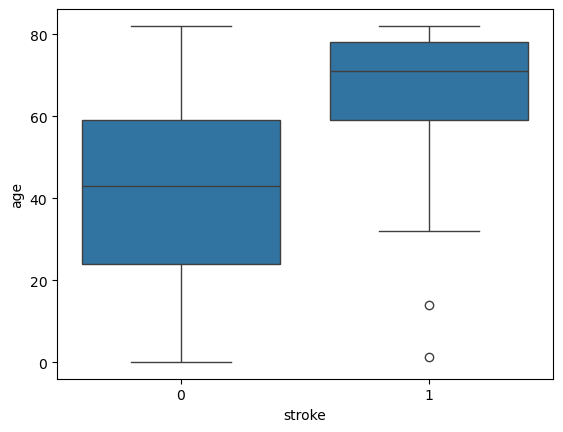

In [28]:
sns.boxplot(x='stroke', y='age', data=df)

<Axes: xlabel='stroke', ylabel='avg_glucose_level'>

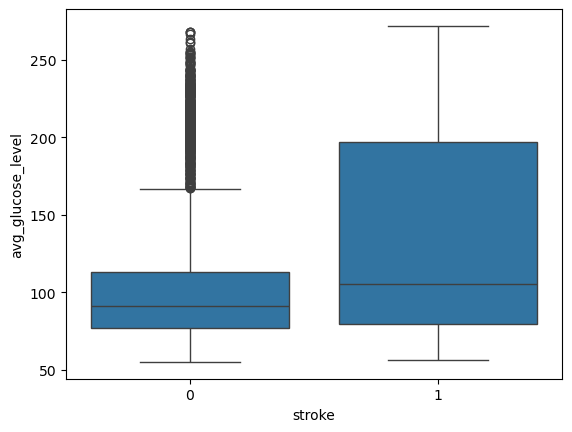

In [29]:
sns.boxplot(x='stroke', y='avg_glucose_level', data=df)

<Axes: xlabel='stroke', ylabel='bmi'>

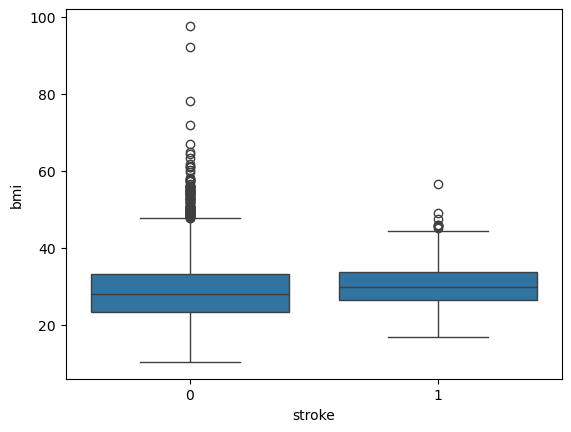

In [30]:
sns.boxplot(x='stroke', y='bmi', data=df)

<Axes: xlabel='heart_disease', ylabel='count'>

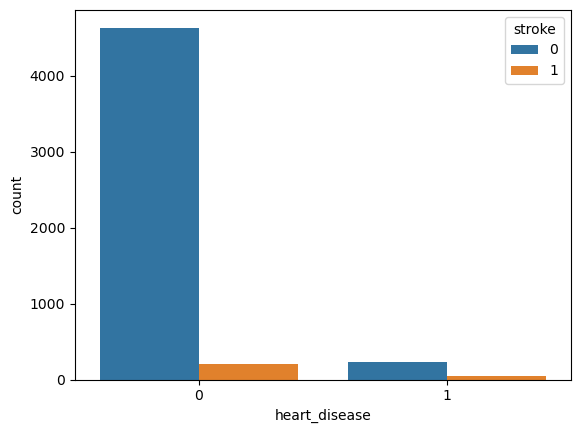

In [31]:
sns.countplot(x='heart_disease', hue='stroke', data=df)

<Axes: xlabel='smoking_status', ylabel='count'>

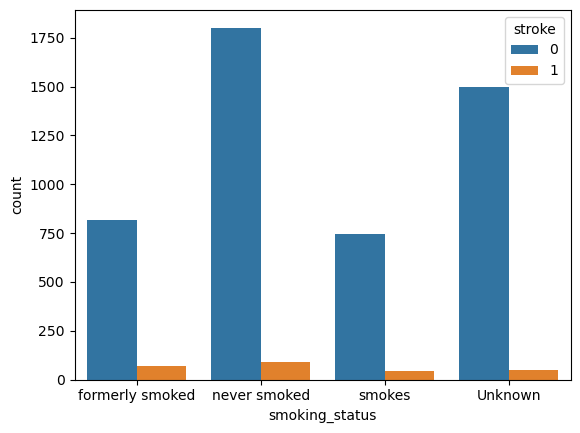

In [32]:
sns.countplot(x='smoking_status', hue='stroke', data=df)

<Axes: xlabel='ever_married', ylabel='count'>

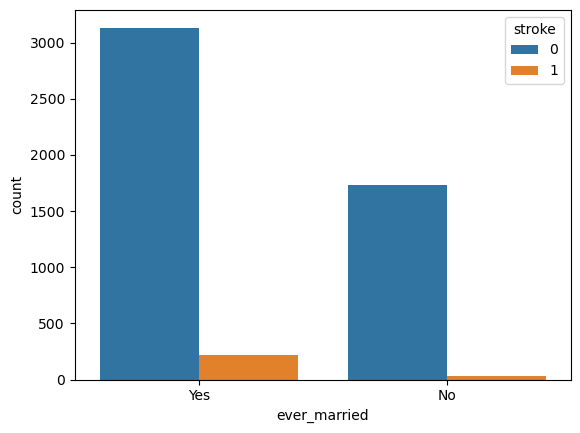

In [33]:
sns.countplot(x='ever_married', hue='stroke', data=df)

In [34]:
df = df[df['gender'] != 'Other']

# Building pipelines

In [35]:
numerical = ['age', 'avg_glucose_level', 'bmi']
categorical = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

In [36]:
X = df.drop('stroke', axis=1)
y = df['stroke']

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical),
    ('cat', categorical_pipeline, categorical)
])

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000))
])

lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.74      0.84       972
           1       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022



Text(50.722222222222214, 0.5, 'Actual')

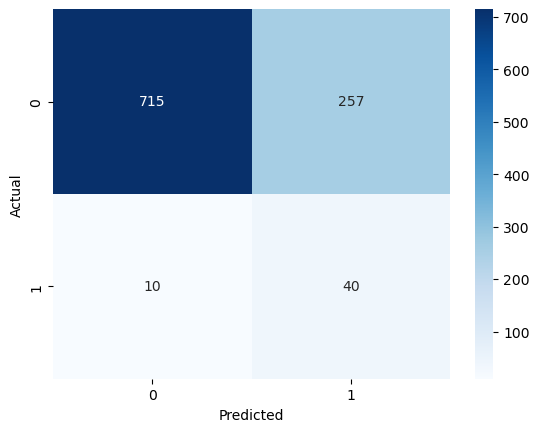

In [40]:
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')

In [41]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42))
])

dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.98      0.74      0.84       972
           1       0.13      0.78      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.76      0.53      1022
weighted avg       0.94      0.74      0.81      1022



In [42]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', max_depth=5, random_state=42))
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.98      0.70      0.82       972
           1       0.12      0.78      0.20        50

    accuracy                           0.70      1022
   macro avg       0.55      0.74      0.51      1022
weighted avg       0.94      0.70      0.79      1022



In [43]:
from sklearn.metrics import recall_score, f1_score

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_rf)],
    'Recall': [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_dt), recall_score(y_test, y_pred_rf)],
    'F1 Score': [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_dt), f1_score(y_test, y_pred_rf)]
})
results

,Model,Accuracy,Recall,F1 Score
0,Logistic Regression,0.738748,0.80,0.230548
1,Decision Tree,0.738748,0.78,0.226087
2,Random Forest,0.701566,0.78,0.203655
